In [2]:
import os, subprocess
import json
import uproot3
import awkward as ak
import numpy as np
from coffea import processor, util, hist
import pickle
import pandas as pd

from plotter import *

In [3]:
lumis = {}
lumis['2016'] = 35.9
lumis['2017'] = 41.5
lumis['2018'] = 59.9

with open('xsec.json') as f:
  xs = json.load(f)

with open('pmap.json') as f:
  pmap = json.load(f)

In [4]:
year = '2017'
nfiles = len(subprocess.getoutput("ls infiles-split/"+year+"*.json").split())
outsum = processor.dict_accumulator()

In [5]:
picklename = 'pickles/'+str(year)+'_templates.pkl'

In [6]:
# Read the histogram from the pickle file

ggf = pickle.load(open(picklename,'rb')).integrate('region','signal-ggf').integrate('systematic','nominal')
vbf = pickle.load(open(picklename,'rb')).integrate('region','signal-vbf').integrate('systematic','nominal')

In [7]:
def significance(s,b):
    if b==0:
        return 0
    z_squared = 2.0*(s+b)*np.log(1.0+1.0*s/b) - 2.0*s
    return np.sqrt(z_squared)

In [8]:
vbf

<Hist (process,pt1,msd1,ddb1) instance at 0x7ff7cb0a77f0>

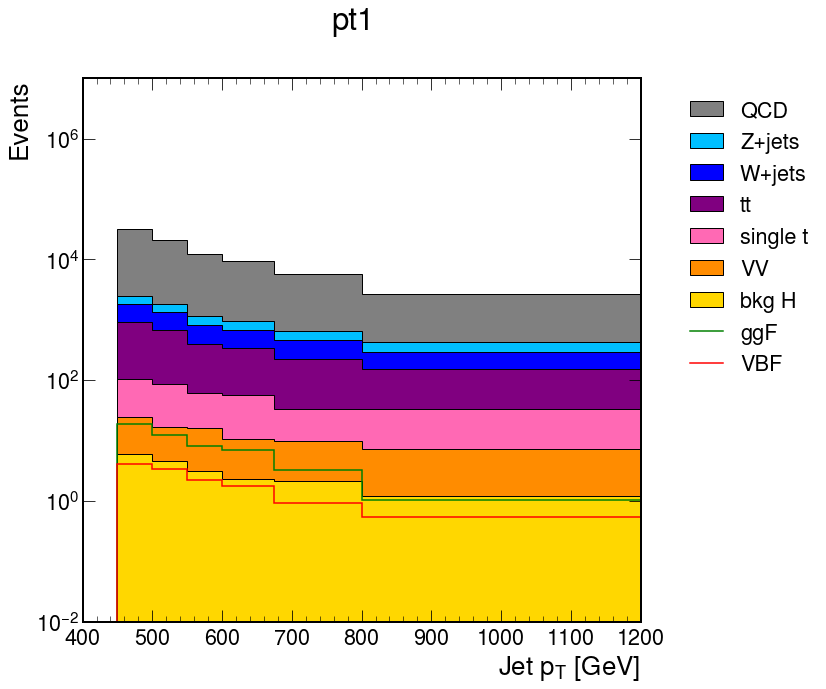

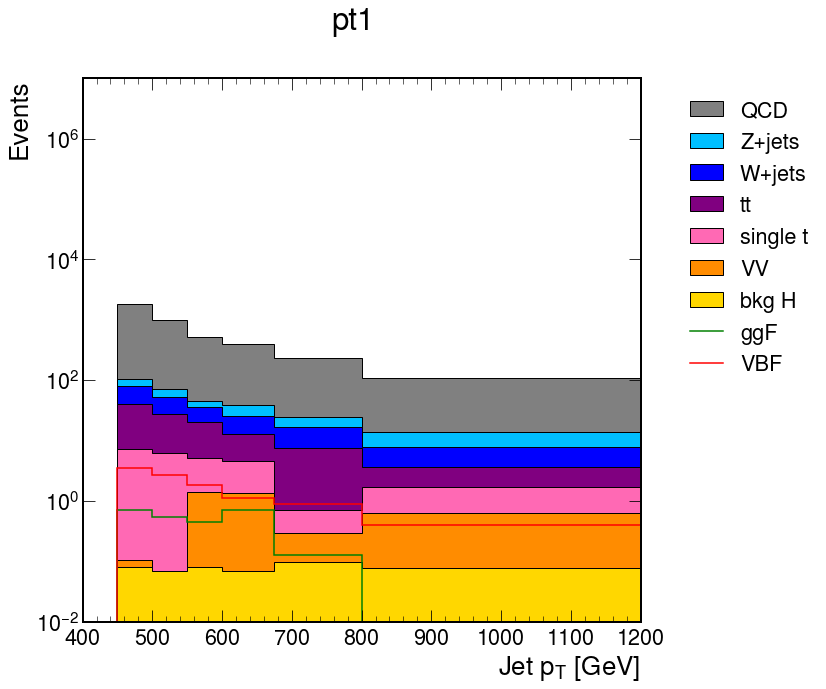

In [9]:
plot_mconly_ggfvbf(ggf.sum('msd1').integrate('ddb1',int_range=slice(0.89,1)),year+'/pt1_ggfcat','pt1')
plot_mconly_ggfvbf(vbf.sum('msd1').integrate('ddb1',int_range=slice(0.89,1)),year+'/pt1_vbfcat','pt1')

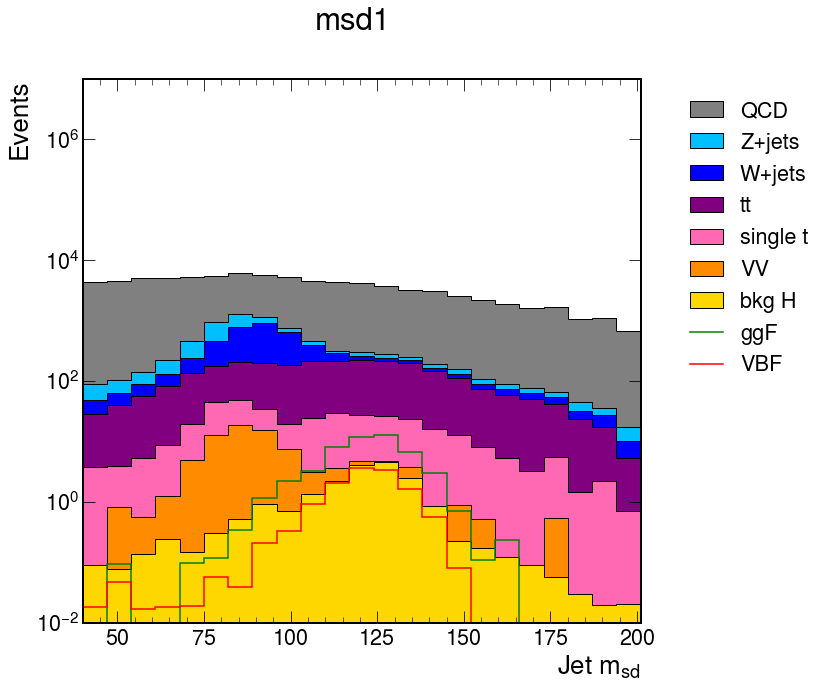

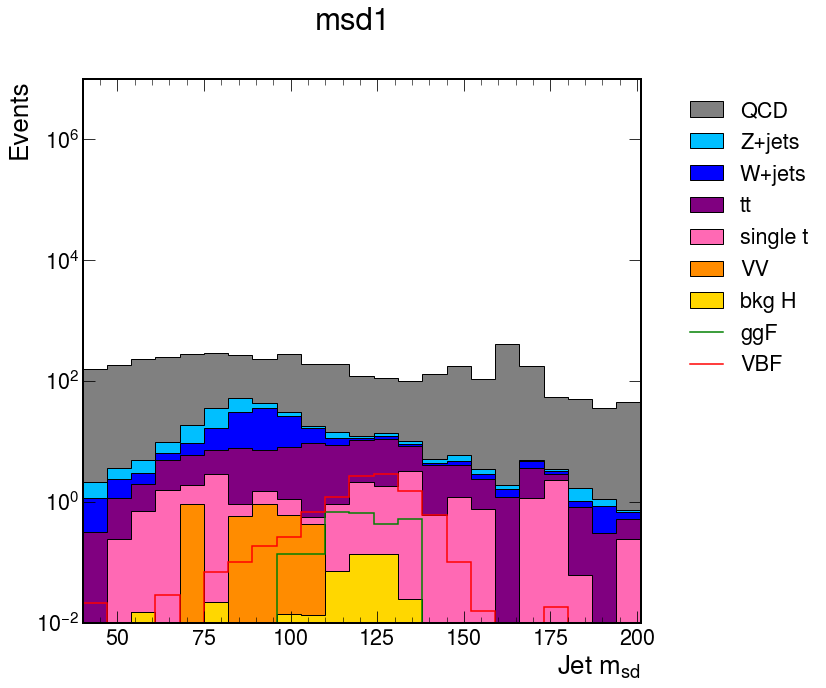

In [10]:
plot_mconly_ggfvbf(ggf.sum('pt1').integrate('ddb1',int_range=slice(0.89,1)),year+'/msd1_ggfcat','msd1')
plot_mconly_ggfvbf(vbf.sum('pt1').integrate('ddb1',int_range=slice(0.89,1)),year+'/msd1_vbfcat','msd1')

In [11]:
# number counting significance only makes sense in the mass window of Higgs
mbb_min = 110
mbb_max = 138

ggf_window=ggf.sum('pt1').integrate('msd1',int_range=slice(mbb_min,mbb_max)).integrate('ddb1',int_range=slice(0.89,1))
vbf_window=vbf.sum('pt1').integrate('msd1',int_range=slice(mbb_min,mbb_max)).integrate('ddb1',int_range=slice(0.89,1))

In [12]:
ggf_sr = ggf_window.values()
vbf_sr = vbf_window.values()

In [13]:
# VBF significance
s1 = ggf_sr[('VBF',)] 
b1 = ggf_sr[('QCD',)] + ggf_sr[('Zjets',)] + ggf_sr[('Wjets',)] + ggf_sr[('VV',)] + ggf_sr[('ttbar',)] + ggf_sr[('singlet',)] + ggf_sr[('ggF',)] + ggf_sr[('WH',)] + ggf_sr[('ZH',)] + ggf_sr[('ttH',)]
Z1 = significance(s1,b1)

s2 = vbf_sr[('VBF',)] 
b2 = vbf_sr[('QCD',)] + vbf_sr[('Zjets',)] + vbf_sr[('Wjets',)] + vbf_sr[('VV',)] + vbf_sr[('ttbar',)] + vbf_sr[('singlet',)] + vbf_sr[('ggF',)] + vbf_sr[('WH',)] + vbf_sr[('ZH',)] + vbf_sr[('ttH',)]
Z2 = significance(s2,b2)

print(Z1,Z2,np.sqrt(Z1*Z1+Z2*Z2))

0.08507866871296889 0.363455378010287 0.3732803124658086


In [14]:
# ggF significance
s1 = ggf_sr[('ggF',)] 
b1 = ggf_sr[('QCD',)] + ggf_sr[('Zjets',)] + ggf_sr[('Wjets',)] + ggf_sr[('VV',)] + ggf_sr[('ttbar',)] + ggf_sr[('singlet',)] + ggf_sr[('VBF',)] + ggf_sr[('WH',)] + ggf_sr[('ZH',)] + ggf_sr[('ttH',)]
Z1 = significance(s1,b1)

s2 = vbf_sr[('ggF',)] 
b2 = vbf_sr[('QCD',)] + vbf_sr[('Zjets',)] + vbf_sr[('Wjets',)] + vbf_sr[('VV',)] + vbf_sr[('ttbar',)] + vbf_sr[('singlet',)] + vbf_sr[('VBF',)] + vbf_sr[('WH',)] + vbf_sr[('ZH',)] + vbf_sr[('ttH',)]
Z2 = significance(s2,b2)

print(Z1,Z2,np.sqrt(Z1*Z1+Z2*Z2))

# this only makes sense in the mass window of Higgs

0.3167393130802115 0.0986507203614955 0.33174652534482746


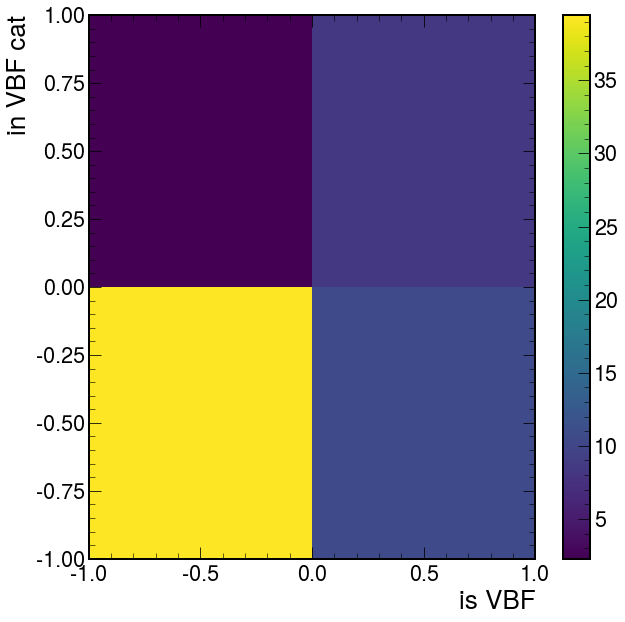

In [15]:
plt.hist2d(x=[-1,-1,1,1],y=[-1,1,-1,1],density=False, weights=[ggf_sr[('ggF',)] ,vbf_sr[('ggF',)] ,ggf_sr[('VBF',)] ,vbf_sr[('VBF',)]],bins=[2,2]);
plt.xlabel('is VBF');
plt.ylabel('in VBF cat');
plt.colorbar()
plt.savefig(year+'/confusion.png')

In [16]:
print(ggf_sr[('ggF',)] ,vbf_sr[('ggF',)] ,ggf_sr[('VBF',)] ,vbf_sr[('VBF',)])

39.4495847158276 2.277893442951558 10.603036512547378 8.360334651515377


In [21]:
ggf.sum('pt1','msd1').integrate('ddb1',int_range=slice(0.89,1)).values()

{('ZH',): 6.578508403919428,
 ('WH',): 7.125930608720933,
 ('ttH',): 5.6726740628173795,
 ('VBF',): 12.940732374013532,
 ('ggF',): 50.65407807294895,
 ('ggF-powheg',): 102.8504986158472,
 ('QCD',): 75278.97244404814,
 ('VV',): 65.66479194335069,
 ('Wjets',): 2095.192361954443,
 ('Zjets',): 2747.8870976654634,
 ('ttbar',): 2332.0744063911343,
 ('singlet',): 290.22922723975705,
 ('data',): 70017.0,
 ('muondata',): 4932.0}

In [22]:
ggf.sum('pt1','msd1').integrate('ddb1',int_range=slice(0,0.89)).values()

{('ZH',): 10.19099769424277,
 ('WH',): 13.963031056360308,
 ('ttH',): 16.05686634077073,
 ('VBF',): 8.014554960058573,
 ('ggF',): 31.26021198062082,
 ('ggF-powheg',): 61.127279139195295,
 ('QCD',): 4902291.749316405,
 ('VV',): 1432.3979343113037,
 ('Wjets',): 98202.94720362395,
 ('Zjets',): 39642.98331310188,
 ('ttbar',): 17524.957871651528,
 ('singlet',): 2962.521078239677,
 ('data',): 4482329.0,
 ('muondata',): 74651.0}

In [23]:
vbf.sum('pt1','msd1').integrate('ddb1',int_range=slice(0.89,1)).values()

{('ZH',): 0.07569924387400634,
 ('WH',): 0.24701569451623087,
 ('ttH',): 0.1553445164949847,
 ('VBF',): 10.42129038482925,
 ('ggF',): 2.555403386777841,
 ('ggF-powheg',): 5.439678487565346,
 ('QCD',): 3784.1081157155877,
 ('VV',): 3.4319583157575275,
 ('Wjets',): 81.28420427664814,
 ('Zjets',): 103.9953764444805,
 ('ttbar',): 86.52226419393966,
 ('singlet',): 21.906001955290307,
 ('data',): 3533.0,
 ('muondata',): 328.0}

In [24]:
vbf.sum('pt1','msd1').integrate('ddb1',int_range=slice(0,0.89)).values()

{('ZH',): 0.1514941701974832,
 ('WH',): 0.30197724967059614,
 ('ttH',): 0.3675323260384835,
 ('VBF',): 5.08841701409381,
 ('ggF',): 0.9368700151805516,
 ('ggF-powheg',): 2.9774638612841047,
 ('QCD',): 187725.3696806578,
 ('VV',): 44.197725467428974,
 ('Wjets',): 3638.768562878627,
 ('Zjets',): 1565.45595296803,
 ('ttbar',): 578.9721202006646,
 ('singlet',): 119.71149351636235,
 ('data',): 194189.0,
 ('muondata',): 4543.0}